# Exploratory Data Analysis: Online Retail Sales

**Goal:** understand sales patterns in a UK-based online retailer's transaction data: when customers buy, what sells best, and where revenue comes from.

**Dataset:** `Online_Retail.xlsx` (UCI Machine Learning Repository), transactions from 01/12/2010 to 09/12/2011.

| Column | Meaning |
|---|---|
| InvoiceNo | Invoice number (prefix `C` = cancellation) |
| StockCode | Product code |
| Description | Product name |
| Quantity | Units per line item |
| InvoiceDate | Timestamp of the invoice |
| UnitPrice | Price per unit (GBP) |
| CustomerID | Customer identifier (often missing) |
| Country | Customer country |

**Analysis steps:** 1) Load, 2) Inspect, 3) Data quality checks, 4) Clean, 5) Feature engineering, 6) Visualise, 7) Findings, 8) Generate PDF report.

In [1]:
import os, json, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import seaborn as sns

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.dpi": 110, "axes.titleweight": "bold", "axes.titlesize": 13})

DATA_PATH = "../Dataset/Online_Retail.xlsx"
VIZ_DIR = "../Visualizations"
REPORT_DIR = "../Reports"
os.makedirs(VIZ_DIR, exist_ok=True); os.makedirs(REPORT_DIR, exist_ok=True)
PRIMARY = "#1F4E79"; ACCENT = "#E07B39"

## 1. Load the data

In [2]:
sheets = pd.ExcelFile(DATA_PATH).sheet_names
IS_SAMPLE = "SAMPLE_DATA_NOTICE" in sheets     # True only for the bundled synthetic sample
df = pd.read_excel(DATA_PATH, sheet_name=0)
print("Using sample (synthetic) data:", IS_SAMPLE)
print("Shape:", df.shape)
df.head()

Using sample (synthetic) data: True
Shape: (48694, 8)


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,539954,85242,STAR FRAME LIGHT,3,2010-12-01 08:11:00,4.24,NaN,United Kingdom
1,539954,85255,STAR LUNCH SET,7,2010-12-01 08:11:00,2.25,NaN,United Kingdom
2,539954,85275,VINTAGE LANTERN TRAY,1,2010-12-01 08:11:00,8.87,NaN,United Kingdom
3,540663,85216,RED TEA BAG,2,2010-12-01 08:16:00,3.90,12670.0,United Kingdom
4,540663,85315A,WOODEN MUG BOX,7,2010-12-01 08:16:00,1.89,12670.0,United Kingdom


## 2. Initial inspection

In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 48694 entries, 0 to 48693
Data columns (total 8 columns):
 #   Column       Non-Null Count  Dtype         
---  ------       --------------  -----         
 0   InvoiceNo    48694 non-null  str           
 1   StockCode    48694 non-null  str           
 2   Description  48613 non-null  str           
 3   Quantity     48694 non-null  int64         
 4   InvoiceDate  48694 non-null  datetime64[us]
 5   UnitPrice    48694 non-null  float64       
 6   CustomerID   36652 non-null  float64       
 7   Country      48694 non-null  str           
dtypes: datetime64[us](1), float64(2), int64(1), str(4)
memory usage: 3.0 MB


In [4]:
df.describe(include="all").T

,count,unique,top,freq,mean,min,25%,50%,75%,max,std
InvoiceNo,48694,5304,536820,47,NaN,NaN,NaN,NaN,NaN,NaN,NaN
StockCode,48694,321,85007A,3649,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Description,48613,321,BLUE CANDLE TIN,3638,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Quantity,48694.0,NaN,NaN,NaN,7.431121,-180.0,2.0,4.0,8.0,222.0,12.378509
InvoiceDate,48694,NaN,NaN,NaN,2011-06-29 12:49:16.460755,2010-12-01 08:11:00,2011-03-10 21:57:45,2011-07-26 12:10:00,2011-10-17 10:51:00,2011-12-11 10:17:00,NaN
UnitPrice,48694.0,NaN,NaN,NaN,2.905858,0.0,1.25,2.1,3.71,18.0,2.43744
CustomerID,36652.0,NaN,NaN,NaN,15317.908927,12351.0,13859.0,15359.0,16794.0,18284.0,1706.311634
Country,48694,14,United Kingdom,42475,NaN,NaN,NaN,NaN,NaN,NaN,NaN


## 3. Data quality checks

In [5]:
quality = pd.DataFrame({
    "missing": df.isna().sum(),
    "missing_%": (df.isna().mean() * 100).round(2),
})
print(quality, "\n")

is_cancel = df["InvoiceNo"].astype(str).str.startswith("C")
print("Duplicate rows          :", df.duplicated().sum())
print("Cancellation lines      :", is_cancel.sum(), f"({is_cancel.mean():.2%})")
print("Negative quantities     :", (df['Quantity'] < 0).sum())
print("Zero / negative prices  :", (df['UnitPrice'] <= 0).sum())
print("Non-product stock codes :", df['StockCode'].astype(str).isin(['POST','D','M','DOT','BANK CHARGES','CRUK']).sum())

             missing  missing_%
InvoiceNo          0       0.00
StockCode          0       0.00
Description       81       0.17
Quantity           0       0.00
InvoiceDate        0       0.00
UnitPrice          0       0.00
CustomerID     12042      24.73
Country            0       0.00 

Duplicate rows          : 250
Cancellation lines      : 906 (1.86%)
Negative quantities     : 905
Zero / negative prices  : 60
Non-product stock codes : 40


## 4. Data cleaning

Decisions taken:
- **Drop exact duplicate rows**, which are repeated records.
- **Remove cancellations** (`InvoiceNo` starts with `C`) and rows with non-positive quantity or price, so that revenue reflects completed sales.
- **Drop rows with a missing Description**, since they can't be attributed to a product.
- **Remove non-product codes** such as postage and manual adjustments.
- **Keep rows with missing CustomerID** for sales analysis (guest checkouts are real revenue) but exclude them from any customer-level metrics.

In [6]:
raw_rows = len(df)
steps = []

d = df.drop_duplicates();                                   steps.append(("Remove duplicate rows", raw_rows - len(d)));  n = len(d)
cancel = d["InvoiceNo"].astype(str).str.startswith("C")
d = d[~cancel];                                             steps.append(("Remove cancelled invoices", n - len(d)));     n = len(d)
d = d[(d["Quantity"] > 0) & (d["UnitPrice"] > 0)];          steps.append(("Remove non-positive quantity/price", n - len(d))); n = len(d)
d = d.dropna(subset=["Description"]);                       steps.append(("Remove missing descriptions", n - len(d)));   n = len(d)
non_product = ["POST", "D", "M", "DOT", "BANK CHARGES", "CRUK", "C2", "S", "B", "AMAZONFEE"]
d = d[~d["StockCode"].astype(str).isin(non_product)];       steps.append(("Remove non-product codes", n - len(d)));      n = len(d)

d["Description"] = d["Description"].str.strip().str.upper()
clean = d.copy()
steps_df = pd.DataFrame(steps, columns=["Cleaning step", "Rows removed"])
print(f"Rows: {raw_rows:,} -> {len(clean):,}  ({len(clean)/raw_rows:.1%} retained)")
steps_df

Rows: 48,694 -> 47,366  (97.3% retained)


,Cleaning step,Rows removed
0,Remove duplicate rows,250
1,Remove cancelled invoices,901
2,Remove non-positive quantity/price,60
3,Remove missing descriptions,78
4,Remove non-product codes,39


## 5. Feature engineering

In [7]:
clean["Revenue"] = clean["Quantity"] * clean["UnitPrice"]
clean["Month"] = clean["InvoiceDate"].dt.to_period("M")
clean["Weekday"] = clean["InvoiceDate"].dt.day_name()
clean["Hour"] = clean["InvoiceDate"].dt.hour
clean[["InvoiceNo", "Description", "Quantity", "UnitPrice", "Revenue", "Month", "Weekday", "Hour"]].head()

,InvoiceNo,Description,Quantity,UnitPrice,Revenue,Month,Weekday,Hour
0,539954,STAR FRAME LIGHT,3,4.24,12.72,2010-12,Wednesday,8
1,539954,STAR LUNCH SET,7,2.25,15.75,2010-12,Wednesday,8
2,539954,VINTAGE LANTERN TRAY,1,8.87,8.87,2010-12,Wednesday,8
3,540663,RED TEA BAG,2,3.90,7.80,2010-12,Wednesday,8
4,540663,WOODEN MUG BOX,7,1.89,13.23,2010-12,Wednesday,8


## 6. Visualisations

### 6.1 Monthly sales trend

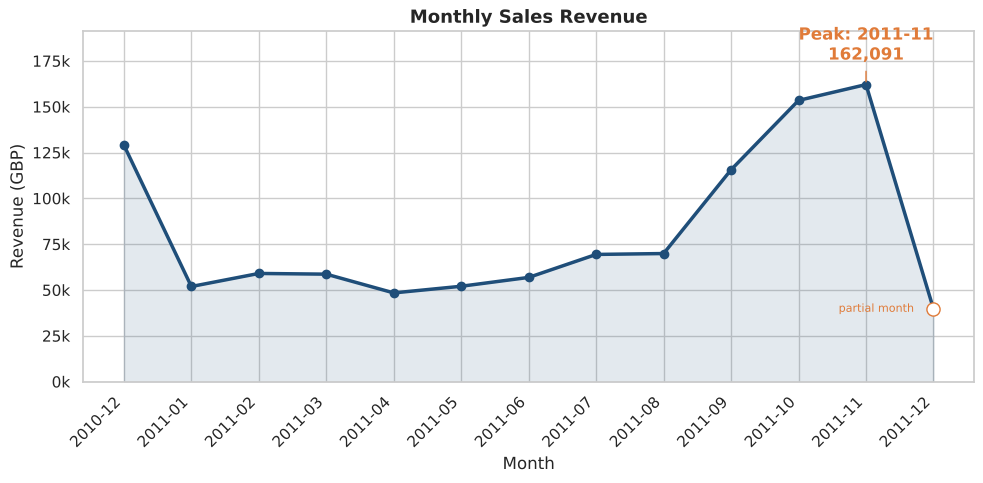

In [8]:
monthly = clean.groupby("Month")["Revenue"].sum()
last_day = clean["InvoiceDate"].max()
partial_last = last_day.day < last_day.days_in_month         # last month is incomplete?

fig, ax = plt.subplots(figsize=(10, 5))
x = monthly.index.astype(str)
ax.plot(x, monthly.values, marker="o", lw=2.5, color=PRIMARY)
ax.fill_between(x, monthly.values, alpha=0.12, color=PRIMARY)
peak = monthly.idxmax()
ax.annotate(f"Peak: {peak}\n{monthly.max():,.0f}", xy=(str(peak), monthly.max()),
            xytext=(0, 18), textcoords="offset points", ha="center", color=ACCENT, fontweight="bold",
            arrowprops=dict(arrowstyle="-", color=ACCENT))
if partial_last:
    ax.scatter([x[-1]], [monthly.values[-1]], s=90, facecolors="white", edgecolors=ACCENT, zorder=5)
    ax.annotate("partial month", xy=(x[-1], monthly.values[-1]), xytext=(-14, 0), textcoords="offset points",
                va="center", ha="right", fontsize=8, color=ACCENT)
ax.set_title("Monthly Sales Revenue")
ax.set_xlabel("Month"); ax.set_ylabel("Revenue (GBP)")
ax.yaxis.set_major_formatter(mtick.FuncFormatter(lambda v, _: f"{v/1000:,.0f}k"))
ax.set_ylim(0, monthly.max() * 1.18)
plt.xticks(rotation=45, ha="right"); plt.tight_layout()
plt.savefig(f"{VIZ_DIR}/Monthly_Sales.png", dpi=150); plt.show()

### 6.2 Top products

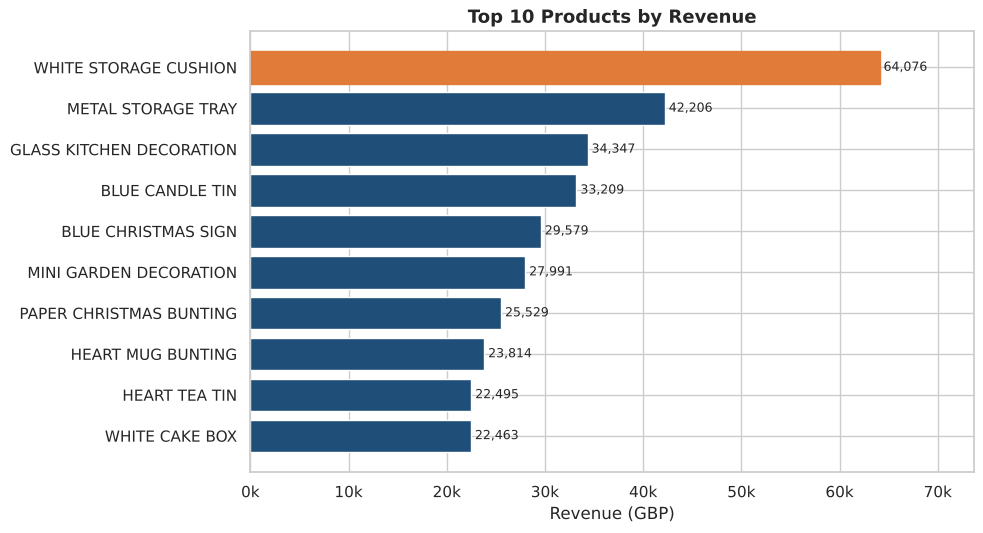

In [9]:
prod = clean.groupby("Description").agg(Revenue=("Revenue", "sum"), Units=("Quantity", "sum")).sort_values("Revenue", ascending=False)
top10 = prod.head(10).iloc[::-1]

fig, ax = plt.subplots(figsize=(10, 5.5))
bars = ax.barh(top10.index, top10["Revenue"], color=PRIMARY)
bars[-1].set_color(ACCENT)
for b, v in zip(bars, top10["Revenue"]):
    ax.text(v, b.get_y() + b.get_height() / 2, f" {v:,.0f}", va="center", fontsize=9)
ax.set_title("Top 10 Products by Revenue")
ax.set_xlabel("Revenue (GBP)"); ax.set_ylabel("")
ax.xaxis.set_major_formatter(mtick.FuncFormatter(lambda v, _: f"{v/1000:,.0f}k"))
ax.set_xlim(0, top10["Revenue"].max() * 1.15)
plt.tight_layout(); plt.savefig(f"{VIZ_DIR}/Top_Products.png", dpi=150); plt.show()

### 6.3 Sales by country

UK share of revenue: 87.0%


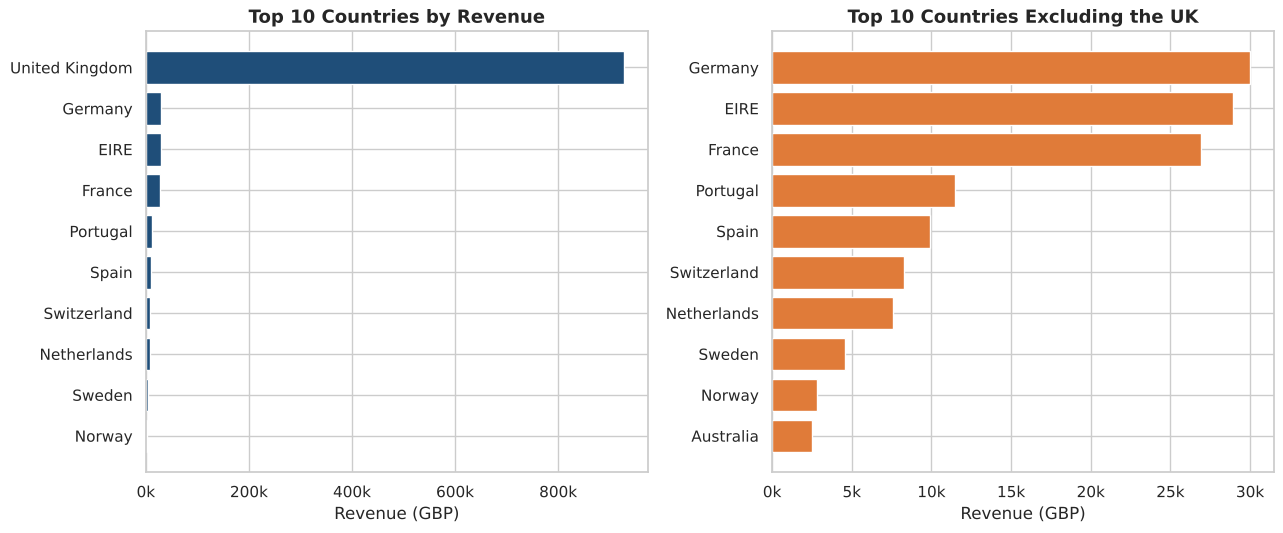

In [10]:
country = clean.groupby("Country")["Revenue"].sum().sort_values(ascending=False)
uk_share = country.get("United Kingdom", 0) / country.sum()
top_c = country.head(10).iloc[::-1]
non_uk = country.drop("United Kingdom", errors="ignore").head(10).iloc[::-1]

fig, axes = plt.subplots(1, 2, figsize=(13, 5.5))
axes[0].barh(top_c.index, top_c.values, color=PRIMARY)
axes[0].set_title("Top 10 Countries by Revenue")
axes[1].barh(non_uk.index, non_uk.values, color=ACCENT)
axes[1].set_title("Top 10 Countries Excluding the UK")
for a in axes:
    a.set_xlabel("Revenue (GBP)"); a.xaxis.set_major_formatter(mtick.FuncFormatter(lambda v, _: f"{v/1000:,.0f}k"))
plt.tight_layout(); plt.savefig(f"{VIZ_DIR}/Country_Sales.png", dpi=150); plt.show()
print(f"UK share of revenue: {uk_share:.1%}")

### 6.4 Extra: when do customers buy?

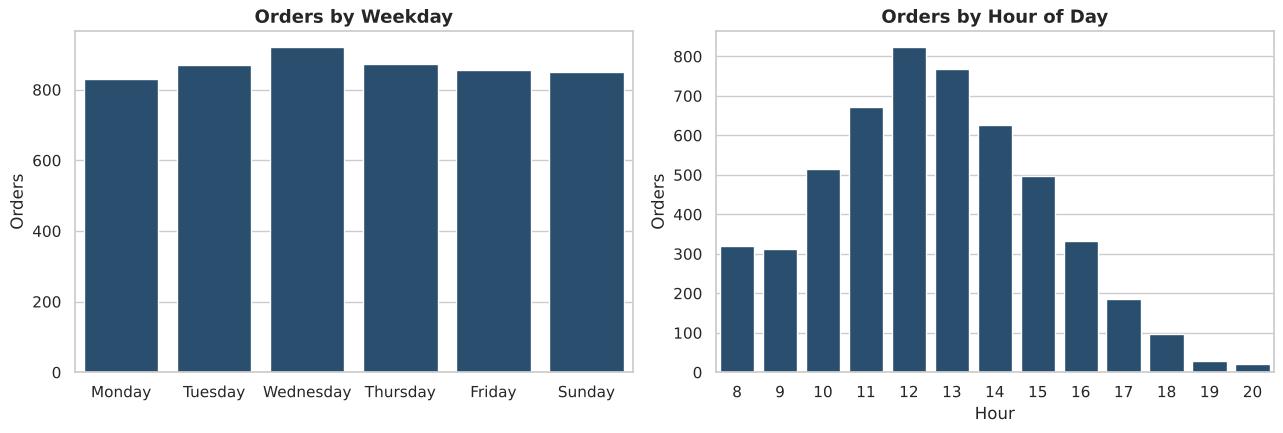

In [11]:
order_level = clean.drop_duplicates("InvoiceNo")
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
wd_order = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
wd = order_level["Weekday"].value_counts().reindex(wd_order).dropna()
sns.barplot(x=wd.index, y=wd.values, color=PRIMARY, ax=axes[0]); axes[0].set_title("Orders by Weekday"); axes[0].set_xlabel(""); axes[0].set_ylabel("Orders")
hr = order_level["Hour"].value_counts().sort_index()
sns.barplot(x=hr.index, y=hr.values, color=PRIMARY, ax=axes[1]); axes[1].set_title("Orders by Hour of Day"); axes[1].set_xlabel("Hour"); axes[1].set_ylabel("Orders")
plt.tight_layout(); plt.show()

## 7. Key metrics and findings

In [12]:
orders = clean.groupby("InvoiceNo")["Revenue"].sum()
cust = clean.dropna(subset=["CustomerID"]).groupby("CustomerID")["Revenue"].sum().sort_values(ascending=False)
top20_share = cust.head(max(1, int(len(cust) * 0.2))).sum() / cust.sum()

R = {
    "is_sample": bool(IS_SAMPLE),
    "raw_rows": int(raw_rows), "clean_rows": int(len(clean)),
    "date_min": str(clean["InvoiceDate"].min().date()), "date_max": str(clean["InvoiceDate"].max().date()),
    "total_revenue": float(clean["Revenue"].sum()),
    "n_orders": int(orders.size), "n_customers": int(cust.size),
    "n_products": int(clean["StockCode"].nunique()), "n_countries": int(clean["Country"].nunique()),
    "aov": float(orders.mean()), "median_order": float(orders.median()),
    "peak_month": str(monthly.idxmax()), "peak_revenue": float(monthly.max()),
    "low_month": str(monthly.iloc[:-1].idxmin() if partial_last else monthly.idxmin()),
    "partial_last_month": bool(partial_last),
    "top_product": prod.index[0], "top_product_rev": float(prod["Revenue"].iloc[0]),
    "top10_product_share": float(prod["Revenue"].head(10).sum() / prod["Revenue"].sum()),
    "top_country": country.index[0], "uk_share": float(uk_share),
    "top_non_uk": country.drop("United Kingdom", errors="ignore").index[0],
    "top_non_uk_rev": float(country.drop("United Kingdom", errors="ignore").iloc[0]),
    "cancel_rate": float(is_cancel.mean()), "missing_cust_pct": float(df["CustomerID"].isna().mean()),
    "busiest_weekday": wd.idxmax(), "busiest_hour": int(hr.idxmax()),
    "top20_cust_share": float(top20_share),
    "steps": [(a, int(b)) for a, b in steps],
}
for k, v in R.items():
    if k != "steps": print(f"{k:22s} {v}")

is_sample              True
raw_rows               48694
clean_rows             47366
date_min               2010-12-01
date_max               2011-12-09
total_revenue          1066119.12
n_orders               5196
n_customers            2046
n_products             320
n_countries            14
aov                    205.18073903002306
median_order           107.845
peak_month             2011-11
peak_revenue           162090.68
low_month              2011-04
partial_last_month     True
top_product            WHITE STORAGE CUSHION
top_product_rev        64075.740000000005
top10_product_share    0.30550915361127756
top_country            United Kingdom
uk_share               0.8699853070827583
top_non_uk             Germany
top_non_uk_rev         29999.510000000002
cancel_rate            0.018605988417464164
missing_cust_pct       0.2472994619460303
busiest_weekday        Wednesday
busiest_hour           12
top20_cust_share       0.5994282889419332


## 8. Generate the PDF report

This cell assembles `Reports/EDA_Project_Report.pdf` from the metrics and charts above, so the report always matches the data in `Dataset/`.

In [13]:
from reportlab.lib.pagesizes import A4
from reportlab.lib import colors
from reportlab.lib.units import cm
from reportlab.lib.styles import getSampleStyleSheet, ParagraphStyle
from reportlab.platypus import SimpleDocTemplate, Paragraph, Spacer, Image, Table, TableStyle, PageBreak, KeepTogether

ss = getSampleStyleSheet()
H1 = ParagraphStyle("H1", parent=ss["Heading1"], textColor=colors.HexColor(PRIMARY), spaceBefore=14, spaceAfter=6)
H2 = ParagraphStyle("H2", parent=ss["Heading2"], textColor=colors.HexColor(PRIMARY))
BODY = ParagraphStyle("Body", parent=ss["BodyText"], fontSize=10.5, leading=15, spaceAfter=6)
CAP = ParagraphStyle("Cap", parent=BODY, fontSize=9, textColor=colors.grey, alignment=1)
TITLE = ParagraphStyle("T", parent=ss["Title"], fontSize=26, textColor=colors.HexColor(PRIMARY), leading=32)
WARN = ParagraphStyle("W", parent=BODY, backColor=colors.HexColor("#FFF3CD"), borderColor=colors.HexColor("#E0B84A"),
                      borderWidth=0.8, borderPadding=7, spaceBefore=8, spaceAfter=12)

def tbl(data, widths):
    t = Table(data, colWidths=widths, repeatRows=1)
    t.setStyle(TableStyle([("BACKGROUND", (0, 0), (-1, 0), colors.HexColor(PRIMARY)), ("TEXTCOLOR", (0, 0), (-1, 0), colors.white),
        ("FONTNAME", (0, 0), (-1, 0), "Helvetica-Bold"), ("FONTSIZE", (0, 0), (-1, -1), 9.5),
        ("ROWBACKGROUNDS", (0, 1), (-1, -1), [colors.white, colors.HexColor("#F2F6FA")]),
        ("GRID", (0, 0), (-1, -1), 0.4, colors.HexColor("#C9D3DD")), ("ALIGN", (1, 0), (-1, -1), "RIGHT"),
        ("TOPPADDING", (0, 0), (-1, -1), 5), ("BOTTOMPADDING", (0, 0), (-1, -1), 5)]))
    return t

def fig(name, caption, width=16.5):
    from PIL import Image as PILImage
    path = f"{VIZ_DIR}/{name}"
    w, h = PILImage.open(path).size
    return KeepTogether([Image(path, width=width * cm, height=width * cm * h / w), Paragraph(caption, CAP), Spacer(1, 8)])

gbp = lambda v: f"GBP {v:,.0f}"
s = []
s += [Spacer(1, 3 * cm), Paragraph("Exploratory Data Analysis<br/>Online Retail Sales", TITLE), Spacer(1, 0.5 * cm),
      Paragraph(f"Transactions from {R['date_min']} to {R['date_max']}", ParagraphStyle("sub", parent=BODY, alignment=1, fontSize=13)), Spacer(1, 0.3 * cm),
      Paragraph("EDA Capstone Project", ParagraphStyle("sub2", parent=BODY, alignment=1, textColor=colors.grey))]
if R["is_sample"]:
    s += [Spacer(1, 1.5 * cm), Paragraph("<b>Data notice:</b> this report was generated from a <b>synthetic sample</b> that mirrors the structure of the "
          "Online Retail dataset. The figures below are illustrative only. Replace <i>Dataset/Online_Retail.xlsx</i> with the real file "
          "and re-run the notebook to produce real results.", WARN)]
s += [PageBreak()]

s += [Paragraph("1. Introduction and objectives", H1),
      Paragraph("This project explores transaction data from a UK-based online retailer that sells giftware, much of it to wholesale customers. "
                "The objectives are to (1) assess data quality and prepare the data for analysis, (2) describe how sales change over time, "
                "(3) identify the products that drive revenue and (4) understand which countries contribute most.", BODY),
      Paragraph("2. Dataset overview", H1),
      Paragraph(f"The raw file holds <b>{R['raw_rows']:,}</b> line items across eight columns (InvoiceNo, StockCode, Description, Quantity, "
                f"InvoiceDate, UnitPrice, CustomerID, Country). Each row is one product line on an invoice.", BODY),
      Paragraph("3. Data cleaning", H1),
      Paragraph(f"Cancellations made up {R['cancel_rate']:.1%} of lines and {R['missing_cust_pct']:.1%} of rows had no CustomerID. "
                f"Rows without a CustomerID were kept for sales analysis but excluded from customer-level metrics.", BODY)]
s += [tbl([["Cleaning step", "Rows removed"]] + [[a, f"{b:,}"] for a, b in R["steps"]] + [["<b>Rows retained</b>".replace("<b>", "").replace("</b>", ""), f"{R['clean_rows']:,}"]], [11 * cm, 4 * cm]), Spacer(1, 10)]

s += [Paragraph("4. Headline metrics", H1),
      tbl([["Metric", "Value"], ["Total revenue", gbp(R["total_revenue"])], ["Completed orders", f"{R['n_orders']:,}"],
           ["Identified customers", f"{R['n_customers']:,}"], ["Distinct products", f"{R['n_products']:,}"], ["Countries", f"{R['n_countries']}"],
           ["Average order value", gbp(R["aov"])], ["Median order value", gbp(R["median_order"])]], [11 * cm, 4 * cm]),
      PageBreak()]

partial = " The final month is incomplete, so its total understates a full month." if R["partial_last_month"] else ""
s += [Paragraph("5. Findings", H1), Paragraph("5.1 Sales over time", H2),
      Paragraph(f"Revenue peaks in <b>{R['peak_month']}</b> at {gbp(R['peak_revenue'])}, while the weakest complete month is <b>{R['low_month']}</b>."
                f"{partial} Orders are concentrated on <b>{R['busiest_weekday']}</b> and around <b>{R['busiest_hour']}:00</b>.", BODY),
      fig("Monthly_Sales.png", "Figure 1. Monthly sales revenue"),
      Paragraph("5.2 Top products", H2),
      Paragraph(f"The best-selling product by revenue is <b>{R['top_product']}</b> ({gbp(R['top_product_rev'])}). "
                f"The top 10 products together account for {R['top10_product_share']:.1%} of revenue.", BODY),
      fig("Top_Products.png", "Figure 2. Top 10 products by revenue"),
      Paragraph("5.3 Sales by country", H2),
      Paragraph(f"<b>{R['top_country']}</b> generates {R['uk_share']:.1%} of revenue. Excluding it, the largest market is "
                f"<b>{R['top_non_uk']}</b> ({gbp(R['top_non_uk_rev'])}). Among identified customers, the top 20% account for "
                f"{R['top20_cust_share']:.1%} of their revenue.", BODY),
      fig("Country_Sales.png", "Figure 3. Revenue by country, with and without the UK"),
      Paragraph("6. Recommendations", H1),
      Paragraph("&bull; <b>Plan inventory around the seasonal peak</b>, building stock ahead of the highest-revenue months.<br/>"
                "&bull; <b>Protect best sellers</b> by monitoring stock levels on the top products, which carry a large share of revenue.<br/>"
                "&bull; <b>Develop international markets</b>, starting with the largest non-domestic country, since revenue is heavily domestic.<br/>"
                "&bull; <b>Improve customer tracking</b>: missing CustomerIDs limit retention and segmentation analysis.<br/>"
                "&bull; <b>Investigate cancellations</b> to find product or fulfilment issues behind returned orders.", BODY),
      Paragraph("7. Limitations", H1),
      Paragraph("The data covers about one year, so seasonality cannot be separated from growth with confidence. Cancelled orders were removed rather than netted off, so revenue is "
                "gross of returns, and rows without a CustomerID cannot be linked to individual customers. This analysis is descriptive and does not establish causes.", BODY)]

def footer(c, doc):
    c.saveState(); c.setFont("Helvetica", 8); c.setFillColor(colors.grey)
    c.drawString(2 * cm, 1.2 * cm, "EDA Capstone Project - Online Retail" + ("  [SAMPLE DATA]" if R["is_sample"] else ""))
    c.drawRightString(A4[0] - 2 * cm, 1.2 * cm, f"Page {doc.page}"); c.restoreState()

SimpleDocTemplate(f"{REPORT_DIR}/EDA_Project_Report.pdf", pagesize=A4, leftMargin=2*cm, rightMargin=2*cm, topMargin=2*cm, bottomMargin=2*cm,
                  title="EDA Project Report - Online Retail", author="EDA Capstone").build(s, onFirstPage=footer, onLaterPages=footer)
print("Report saved to", f"{REPORT_DIR}/EDA_Project_Report.pdf")

Report saved to ../Reports/EDA_Project_Report.pdf


## 9. Interactive dashboard

Builds `Dashboard/Sales_Dashboard.html`: KPI cards plus interactive charts. Open it in any browser (needs internet for the chart library).

In [14]:
DASH_DIR = "../Dashboard"; os.makedirs(DASH_DIR, exist_ok=True)
mlabels = list(monthly.index.astype(str))
if partial_last: mlabels[-1] += " *"
D = {
 "sample": bool(IS_SAMPLE), "range": f"{R['date_min']} to {R['date_max']}", "partial": bool(partial_last),
 "kpi": [["Total revenue", f"GBP {R['total_revenue']:,.0f}"], ["Orders", f"{R['n_orders']:,}"], ["Customers", f"{R['n_customers']:,}"],
         ["Avg order value", f"GBP {R['aov']:,.0f}"], ["Products", f"{R['n_products']:,}"], ["Countries", str(R['n_countries'])]],
 "monthly": [mlabels, [round(v) for v in monthly.values]],
 "products": [list(prod.head(10).index), [round(v) for v in prod["Revenue"].head(10)]],
 "countries": [list(country.head(8).index), [round(v) for v in country.head(8)]],
 "weekday": [list(wd.index), [int(v) for v in wd.values]],
 "hour": [[f"{int(h)}:00" for h in hr.index], [int(v) for v in hr.values]],
 "insights": [f"Peak month: {R['peak_month']} (GBP {R['peak_revenue']:,.0f})",
              f"Top product: {R['top_product']}",
              f"{R['top_country']} = {R['uk_share']:.0%} of revenue; top export market: {R['top_non_uk']}",
              f"Busiest day: {R['busiest_weekday']}, busiest hour: {R['busiest_hour']}:00",
              f"Top 20% of customers = {R['top20_cust_share']:.0%} of identified revenue",
              f"Cancellations: {R['cancel_rate']:.1%} of lines; missing CustomerID: {R['missing_cust_pct']:.1%}"],
}
TEMPLATE = """<!DOCTYPE html><html lang="en"><head><meta charset="utf-8"><title>Online Retail Sales Dashboard</title>
<meta name="viewport" content="width=device-width, initial-scale=1, viewport-fit=cover">
<script src="https://cdnjs.cloudflare.com/ajax/libs/Chart.js/4.4.1/chart.umd.min.js"></script>
<style>
:root{--bg:#f3f6fa;--card:#fff;--text:#1b2733;--mute:#6b7a89;--line:#e1e8ef;--p:#1F4E79;--a:#E07B39;--warn:#fff3cd;--warnt:#6b5200;box-sizing:border-box;padding-top:env(safe-area-inset-top,0px);padding-bottom:env(safe-area-inset-bottom,0px)}
@media (prefers-color-scheme:dark){:root:not([data-theme="light"]){--bg:#0f1720;--card:#18232f;--text:#e8eef4;--mute:#93a3b3;--line:#27384a;--p:#6fa8dc;--a:#f0a066;--warn:#3a3112;--warnt:#f5dd8a;color-scheme:dark}}
*{box-sizing:border-box}body{margin:0;background:var(--bg);color:var(--text);font-family:Inter,Segoe UI,Roboto,Helvetica,Arial,sans-serif}
header{background:var(--p);color:#fff;padding:22px 28px}header h1{margin:0;font-size:22px}header p{margin:4px 0 0;opacity:.85;font-size:13px}
main{max-width:1240px;margin:0 auto;padding:20px 20px 40px}
.warn{background:var(--warn);color:var(--warnt);border-radius:8px;padding:10px 14px;margin-bottom:16px;font-size:13px}
.kpis{display:grid;grid-template-columns:repeat(auto-fit,minmax(170px,1fr));gap:14px;margin-bottom:16px}
.kpi,.card{background:var(--card);border:1px solid var(--line);border-radius:12px;padding:16px}
.kpi span{display:block;color:var(--mute);font-size:12px;text-transform:uppercase;letter-spacing:.05em}.kpi b{display:block;font-size:24px;margin-top:6px;color:var(--p)}
.grid{display:grid;grid-template-columns:repeat(12,1fr);gap:14px}.s7{grid-column:span 7}.s5{grid-column:span 5}.s6{grid-column:span 6}.s12{grid-column:span 12}
.card h2{margin:0 0 10px;font-size:14px}.box{position:relative;height:280px}
ul{margin:0;padding-left:18px;line-height:1.9;font-size:14px}.note{color:var(--mute);font-size:12px;margin-top:14px}
@media(max-width:860px){.s7,.s5,.s6{grid-column:span 12}}
</style></head><body>
<header><h1>Online Retail Sales Dashboard</h1><p id="range"></p></header>
<main><div id="warn"></div><div class="kpis" id="kpis"></div>
<div class="grid">
<div class="card s7"><h2>Monthly revenue (GBP)</h2><div class="box"><canvas id="c1"></canvas></div></div>
<div class="card s5"><h2>Revenue by country (top 8)</h2><div class="box"><canvas id="c2"></canvas></div></div>
<div class="card s12"><h2>Top 10 products by revenue (GBP)</h2><div class="box"><canvas id="c3"></canvas></div></div>
<div class="card s6"><h2>Orders by weekday</h2><div class="box"><canvas id="c4"></canvas></div></div>
<div class="card s6"><h2>Orders by hour</h2><div class="box"><canvas id="c5"></canvas></div></div>
<div class="card s12"><h2>Key insights</h2><ul id="ins"></ul></div></div>
<p class="note" id="note"></p></main>
<script>
const D=__DATA__;const cs=getComputedStyle(document.documentElement);const v=n=>cs.getPropertyValue(n).trim();
document.getElementById("range").textContent="Transactions "+D.range;
if(D.sample)document.getElementById("warn").innerHTML='<div class="warn"><b>Sample data:</b> figures are synthetic and illustrative. Replace the dataset and re-run the notebook for real results.</div>';
document.getElementById("kpis").innerHTML=D.kpi.map(k=>'<div class="kpi"><span>'+k[0]+'</span><b>'+k[1]+'</b></div>').join("");
document.getElementById("ins").innerHTML=D.insights.map(i=>"<li></li>").join("");
document.querySelectorAll("#ins li").forEach((li,i)=>li.textContent=D.insights[i]);
document.getElementById("note").textContent=D.partial?"* The final month is incomplete. Revenue excludes cancellations and non-product codes.":"Revenue excludes cancellations and non-product codes.";
Chart.defaults.color=v("--mute");Chart.defaults.font.family="Inter,Segoe UI,Roboto,Arial,sans-serif";
const grid={color:v("--line")};const fmt=x=>x>=1000?(x/1000).toFixed(0)+"k":x;
const mk=(id,type,d,o={})=>new Chart(document.getElementById(id),{type,data:{labels:d[0],datasets:[{data:d[1],backgroundColor:o.bg||v("--p"),borderColor:o.bc||v("--p"),borderWidth:o.bw||0,fill:o.fill||false,tension:.3,borderRadius:4}]},
options:{responsive:true,maintainAspectRatio:false,indexAxis:o.axis||"x",plugins:{legend:{display:false}},scales:{x:{grid:{display:false},ticks:{callback:o.axis?fmt:undefined}},y:{grid,ticks:{callback:o.axis?undefined:fmt}}}}});
mk("c1","line",D.monthly,{bg:v("--p")+"22",bc:v("--p"),bw:3,fill:true});
mk("c2","bar",D.countries,{axis:"y",bg:v("--a")});
mk("c3","bar",D.products,{axis:"y"});mk("c4","bar",D.weekday);mk("c5","bar",D.hour,{bg:v("--a")});
</script></body></html>"""
html = TEMPLATE.replace("__DATA__", json.dumps(D))
with open(f"{DASH_DIR}/Sales_Dashboard.html", "w", encoding="utf-8") as f: f.write(html)
print("Dashboard saved to", f"{DASH_DIR}/Sales_Dashboard.html", f"({len(html)/1024:.0f} KB)")

Dashboard saved to ../Dashboard/Sales_Dashboard.html (6 KB)


## 10. Conclusions

- Sales are **seasonal**, with a clear revenue peak. Inventory and marketing should be planned around it.
- A **small group of products and a small group of customers** drive a large share of revenue.
- The business is **heavily dependent on its home market**, so international growth is an open opportunity.
- **Data quality** (missing CustomerIDs, cancellations) limits customer-level analysis and is worth fixing at source.

**Next steps:** RFM customer segmentation, market-basket analysis, and a forecasting model for monthly revenue.